# Task 1: Anti-cheat pre-filter (binary classification, F2)

**Goal.** Predict `is_cheater` so that likely cheaters are reviewed first. Metric: F2 of the positive class (recall counts 4x as much as precision).

**Final method (as submitted to Kaggle).**
1. Drop rows whose label is missing (about 13% of train); keep NaNs in the features (LightGBM handles them natively).
2. Two LightGBM binary models, 5-fold stratified CV (seed 342): one on the raw columns, one on raw + 5 engineered features.
3. Test probability = mean of the 5 fold models, then mean of the two variants.
4. Decision threshold **0.18**, chosen on the out-of-fold (OOF) predictions as the maximiser of the *plain* F2 (the Kaggle page says "macro", but the score behaves like plain F2).

**Result.** OOF AUC about 0.891, OOF F2 about 0.837. Output: `../outputs/task1_pred.npy` (0/1 per test row, in `test.csv` row order).

In [1]:
import os, re, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

# ---- configuration -------------------------------------------------------------------------------
# DATA = folder of the Kaggle download that holds 01_binary_classification/ ... 05_anomaly_detection/ and sample_submission.csv
DATA = Path(os.environ.get("CPE342_DATA", "")).expanduser()
assert (DATA / "01_binary_classification").exists(), "Set the environment variable CPE342_DATA to the Kaggle download folder (see ../README.md)"
OUT = Path(os.environ.get("CPE342_OUT", "../outputs")); OUT.mkdir(parents=True, exist_ok=True)   # shared by all notebooks
SEED = 342                                   # every random split / model seed in the project
NJOBS = int(os.environ.get("NJOBS", 16))     # LightGBM threads
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, fbeta_score

## 1. Data and quick EDA

In [2]:
d1 = DATA / "01_binary_classification"
tr, te = pd.read_csv(d1 / "train.csv"), pd.read_csv(d1 / "test.csv")
lab = tr.dropna(subset=["is_cheater"]).reset_index(drop=True)       # rows with a label
y = lab.is_cheater.astype(int).values
feat = [c for c in lab.columns if c not in ("player_id", "is_cheater")]
print(f"train rows {len(tr):,} | labelled {len(lab):,} ({len(lab)/len(tr):.1%}) | test rows {len(te):,} | predictive columns {len(feat)}")
print(f"cheater share among labelled rows: {y.mean():.3f}")
miss = pd.DataFrame({"train_missing": lab[feat].isna().mean(), "test_missing": te[feat].isna().mean()})
miss["diff"] = miss.test_missing - miss.train_missing
print("columns whose missing-value rate differs most between train and test:")
print(miss.reindex(miss["diff"].abs().sort_values(ascending=False).index).head(5).round(3).to_string())

train rows 104,000 | labelled 90,816 (87.3%) | test rows 25,889 | predictive columns 31
cheater share among labelled rows: 0.349
columns whose missing-value rate differs most between train and test:
                        train_missing  test_missing   diff
avg_session_length_min          0.229         0.016 -0.214
aiming_smoothness               0.208         0.021 -0.188
friend_network_size             0.223         0.047 -0.175
account_age_days                0.145         0.006 -0.139
movement_pattern_score          0.225         0.087 -0.137


## 2. Features and cross-validated LightGBM
Engineered features: number of missing values, reports per account age, kill/death x headshot, total aim score, reaction x consistency.

In [3]:
def make_features(df, engineered):
    X = df[feat].copy()
    if engineered:
        X["n_missing"] = df[feat].isna().sum(axis=1)
        X["reports_per_age"] = df.reports_received / (df.account_age_days + 1)
        X["kd_x_hs"] = df.kill_death_ratio * df.headshot_percentage
        X["aim_total"] = df.accuracy_score * df.aiming_smoothness
        X["react_x_cons"] = df.reaction_time_ms * df.input_consistency_score
    return X

PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=31, min_child_samples=40, feature_fraction=0.7,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, verbose=-1, seed=SEED, n_jobs=NJOBS)

def run_cv(engineered):
    X, Xte = make_features(lab, engineered), make_features(te, engineered)
    oof, pte = np.zeros(len(X)), np.zeros(len(Xte))
    for k, (a, b) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y)):
        m = lgb.train(PARAMS, lgb.Dataset(X.iloc[a], y[a]), 3000, valid_sets=[lgb.Dataset(X.iloc[b], y[b])],
                      callbacks=[lgb.early_stopping(150, verbose=False)])
        oof[b] = m.predict(X.iloc[b], num_iteration=m.best_iteration)
        pte += m.predict(Xte, num_iteration=m.best_iteration) / 5
        print(f"  fold {k}: trees {m.best_iteration}, AUC {roc_auc_score(y[b], oof[b]):.4f}", flush=True)
    return oof, pte

print("raw columns:");        oof_raw, te_raw = run_cv(False)
print("raw + engineered:");   oof_fe, te_fe = run_cv(True)
oof, pte = (oof_raw + oof_fe) / 2, (te_raw + te_fe) / 2
print(f"OOF AUC raw {roc_auc_score(y, oof_raw):.4f} | engineered {roc_auc_score(y, oof_fe):.4f} | average {roc_auc_score(y, oof):.4f}")

raw columns:


  fold 0: trees 832, AUC 0.8923


  fold 1: trees 833, AUC 0.8932


  fold 2: trees 709, AUC 0.8903


  fold 3: trees 793, AUC 0.8883


  fold 4: trees 728, AUC 0.8914


... (3 outputs left out)

  fold 2: trees 952, AUC 0.8898


  fold 3: trees 1215, AUC 0.8879


  fold 4: trees 1280, AUC 0.8907


OOF AUC raw 0.8911 | engineered 0.8906 | average 0.8914


## 3. Threshold for the plain F2
F2 = 5PR/(4P+R) weights recall four times as much as precision, so the best threshold is far below 0.5. We scan the OOF predictions and use **0.18** (the OOF maximiser).

OOF-optimal threshold for plain F2: 0.175 (F2 0.8373) | used: 0.18 (OOF F2 0.8371)


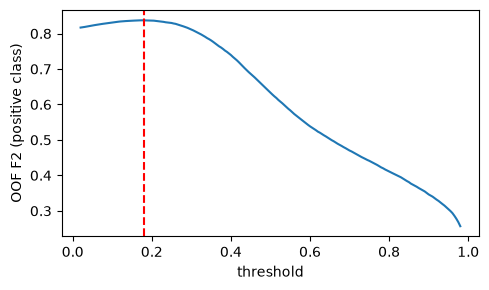

In [4]:
grid = np.round(np.arange(0.02, 0.98 + 1e-9, 0.005), 3)
f2 = np.array([fbeta_score(y, oof >= t, beta=2, zero_division=0) for t in grid])
best_t = float(grid[f2.argmax()])
THRESHOLD = 0.18                                   # value used for the Kaggle submission
print(f"OOF-optimal threshold for plain F2: {best_t:.3f} (F2 {f2.max():.4f}) | used: {THRESHOLD} (OOF F2 {fbeta_score(y, oof >= THRESHOLD, beta=2):.4f})")
np.save(OUT / "task1_f2_curve.npy", np.c_[grid, f2])
try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(5, 3)); plt.plot(grid, f2); plt.axvline(THRESHOLD, color="r", ls="--"); plt.xlabel("threshold"); plt.ylabel("OOF F2 (positive class)"); plt.tight_layout(); plt.show()
except Exception as e:
    print("plot skipped:", e)

In [5]:
pred = (pte >= THRESHOLD).astype(int)
np.save(OUT / "task1_test_prob.npy", pte); np.save(OUT / "task1_pred.npy", pred)
print(f"test rows flagged: {pred.sum():,} ({pred.mean():.1%}) | saved ../outputs/task1_pred.npy")

test rows flagged: 15,597 (60.2%) | saved ../outputs/task1_pred.npy
